In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split

# 1. Load data and prepare features/target (same steps as Morayo's notebook)
df = pd.read_csv("road_crash_prediction/collisions_merged_clean.csv")
df = df.drop(columns=["collision_index", "collision_ref_no"])

y = df["collision_severity"]
X = df.drop(columns=["collision_severity"])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

# 2. Train the max_depth=10 model
model_depth = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
)
model_depth.fit(X_train, y_train)

y_pred_depth = model_depth.predict(X_test)
print(f"Depth=10 Accuracy: {accuracy_score(y_test, y_pred_depth):.2%}\n")
print(classification_report(y_test, y_pred_depth))

C:\Users\SMC\AppData\Local\Temp\ipykernel_23176\3760046400.py:15: DtypeWarning: Columns (0: collision_index, 1: collision_ref_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("road_crash_prediction/collisions_merged_clean.csv")


Depth=10 Accuracy: 52.56%

              precision    recall  f1-score   support

           1       0.04      0.59      0.08       300
           2       0.31      0.41      0.36      4714
           3       0.85      0.56      0.67     15172

    accuracy                           0.53     20186
   macro avg       0.40      0.52      0.37     20186
weighted avg       0.71      0.53      0.59     20186



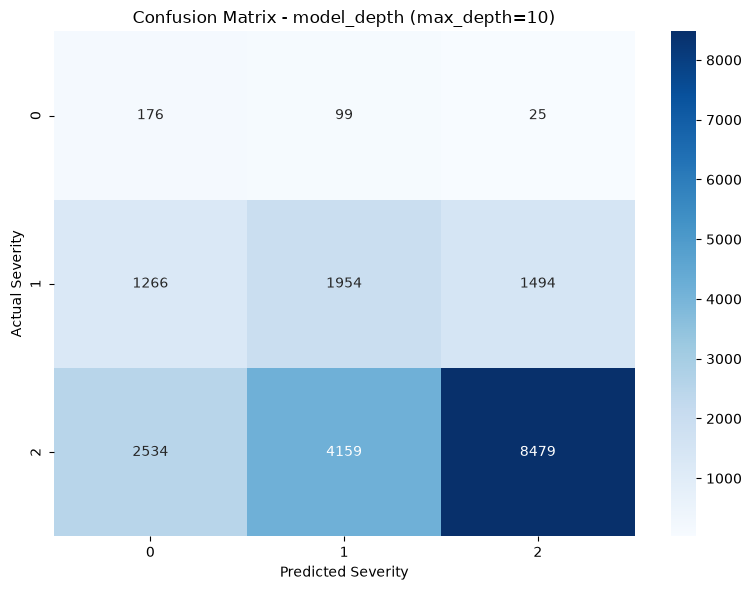

In [7]:
cm = confusion_matrix(y_test, y_pred_depth)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - model_depth (max_depth=10)")
plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.tight_layout()
plt.show()

Top 3 most important features:
1. did_police_officer_attend_scene_of_accident (0.1924)
2. speed_limit (0.1004)
3. urban_or_rural_area (0.0623)


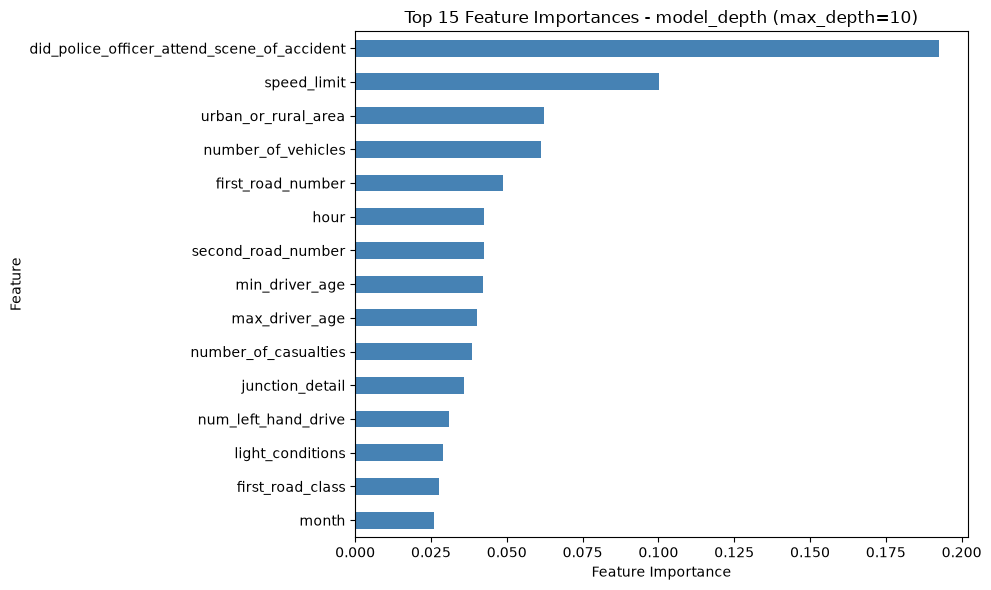

In [8]:
top_15 = (
    pd.Series(model_depth.feature_importances_, index=X_train.columns)
    .sort_values(ascending=False)
    .head(15)
)

print("Top 3 most important features:")
for idx, (name, score) in enumerate(top_15.head(3).items(), start=1):
    print(f"{idx}. {name} ({score:.4f})")

plt.figure(figsize=(10, 6))
top_15.sort_values(ascending=True).plot(kind="barh", color="steelblue")
plt.title("Top 15 Feature Importances - model_depth (max_depth=10)")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Model Evaluation Report (`max_depth=10`)

### Dataset & Robustness
This model was trained on the combined **2023 and 2024 collision dataset (100,927 rows total)**. Having two full years of combined data (over 100k rows) gives much stronger coverage across road types, lighting, weather, and crash severity cases than training on a single year alone, making the results more robust.

### Accuracy Trade-Off (69% Default vs. ~52.6% `max_depth=10`)
The default model gets around **69% accuracy**, while the `max_depth=10` model gets around **52.6% accuracy**. The reason accuracy drops is that `max_depth=10` actually tries to predict **Fatal** crashes rather than mostly ignoring them—boosting Fatal crash recall at the cost of lower overall accuracy and more false alarms on other classes.

### Top 3 Most Important Features Predicting Severity
1. did_police_officer_attend_scene_of_accident — Top split feature in `model_depth` (`max_depth=10`).
2. speed_limit — Second-most important feature for separating severity levels.
3. urban_or_rural_area — Third-most important feature for separating severity levels.

### Limitations
- **Class imbalance:** Fatal crashes make up a very small share of the 100,927 records compared to less severe crashes, so overall accuracy alone doesn't capture performance on rare high-severity events.
- **Data & feature limits:** Results still depend on what features were recorded and how consistently severity was reported in the underlying data.